# Big Data Bowl 2027 — Injury Projection from Season Tracking, and Pitch Figures

**Question:** does a player's game tracking in one season project an injury in the **next** season?

Season pairs: 2023 → 2024 (2023 class) and 2024 → 2025 (2023 and 2024 classes). Season features come from the rep-level measures the cross-position notebook already cached (`outputs/cross_position/<family>_reps.parquet`), so **run that notebook first**. The outcome uses the same injury definition as the rookie-injury notebook.

**Pre-specified tests** (recorded in the findings doc on Nov 16, 2026, before running):

| Test | Prediction | Families |
|---|---|---|
| P1 | Players injured next season had a more negative **top-speed trend** this season | All four |
| P2 | Players injured next season kept **less speed through cuts** this season | DBs, receivers |
| P3 | Season tracking features improve cross-validated AUC over position, draft round, and usage (descriptive) | All four |

Section 4 makes the figures for the pitch: the reliability-by-reps curve, the held-out test results, and the DB load-then-decline sequence.

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

DATA, EXT = Path("../data"), Path("external")
CACHE = Path("outputs/cross_position")
OUT_DIR, FIG_DIR = Path("outputs/projection"), Path("outputs/pitch_figures")
USE_SYNTHETIC = not (DATA / "games.csv").exists()
for d in [OUT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEASON_PAIRS = [(2023, 2024), (2024, 2025)]
MIN_GAMES_T = 4            # tracked games (5+ reps) needed in season t
MIN_GAMES_NEXT = 4         # games played in season t+1 (exposure)
IR_MIN_GAMES = 3
EXCLUDE_INJURY = "concussion|head|illness|personal|rest|not injury|non-football"
FAMILIES = {"db": ("DB", {"CB", "FS", "SS", "S", "DB"}, "cutting"),
            "receivers": ("Receivers", {"WR", "TE"}, "cutting"),
            "ol": ("OL", {"T", "G", "C"}, "burst"),
            "front7": ("Front seven", {"DE", "DT", "NT", "OLB", "ILB", "MLB", "LB"}, "burst")}

if USE_SYNTHETIC:
    from synthetic_projection import make_all
    S = make_all()
    games, players, ext_players = S["games"], S["players"], S["ext_players"]
    injuries, snaps, schedule, REPS = S["injuries"], S["snaps"], S["schedule"], S["reps"]
else:
    games = pd.read_csv(DATA / "games.csv")
    players = pd.read_csv(DATA / "players.csv")
    ext_players = pd.read_csv(EXT / "players.csv", usecols=["gsis_id", "nfl_id", "pfr_id", "display_name", "position"])
    injuries = pd.concat(pd.read_csv(EXT / f"injuries_{y}.csv") for y in [2023, 2024, 2025])
    import nflreadpy as nfl
    snaps = nfl.load_snap_counts([2023, 2024, 2025]).to_pandas()
    schedule = nfl.load_schedules([2023, 2024, 2025]).to_pandas()
    REPS = {}
    for key in FAMILIES:
        f = CACHE / f"{key}_reps.parquet"
        if not f.exists():
            raise FileNotFoundError(f"{f} not found: run bdb2027_cross_position_injury_risk.ipynb first")
        REPS[key] = pd.read_parquet(f)

games = games.rename(columns={"game_id": "gameId"})
games = games[games.season_type.astype(str).str.upper().str.startswith("REG")]
idmap = ext_players.dropna(subset=["nfl_id"]).copy()
idmap["nfl_id"] = idmap.nfl_id.astype(int)
players["draft_round"] = pd.to_numeric(players.get("draft_round"), errors="coerce").fillna(8)
print("Synthetic demo mode" if USE_SYNTHETIC else "Real data")
print({k: f"{len(v):,} reps" for k, v in REPS.items()})

Real data
{'db': '66,426 reps', 'receivers': '45,042 reps', 'ol': '86,539 reps', 'front7': '52,584 reps'}


## 1. Outcome: injury in the next season

Same definition as the rookie-injury notebook, for any season: weeks listed Out with an injury, plus absences of 3+ team games starting right after an injury listing (injured reserve). Exposure in the next season: games played and usage (snaps per game played).

In [2]:
def season_outcome(season, ids):
    inj = injuries[(injuries.game_type == "REG") & (injuries.season == season)].merge(idmap[["gsis_id", "nfl_id"]], on="gsis_id")
    inj = inj[inj.nfl_id.isin(ids) & inj.report_primary_injury.notna()
              & ~inj.report_primary_injury.astype(str).str.lower().str.contains(EXCLUDE_INJURY)]
    out_weeks = inj[inj.report_status == "Out"].groupby("nfl_id").week.apply(set).to_dict()
    listed = inj.groupby("nfl_id").week.apply(set).to_dict()
    sn = snaps[(snaps.game_type == "REG") & (snaps.season == season)].merge(
        idmap[["pfr_id", "nfl_id"]], left_on="pfr_player_id", right_on="pfr_id")
    sn = sn[sn.nfl_id.isin(ids)]
    sch = schedule[(schedule.game_type == "REG") & (schedule.season == season)]
    team_weeks = (pd.concat([sch[["week", "home_team"]].rename(columns={"home_team": "team"}),
                             sch[["week", "away_team"]].rename(columns={"away_team": "team"})])
                    .groupby("team").week.apply(lambda w: sorted(set(w))).to_dict())
    by_player = {k: g for k, g in sn.groupby("nfl_id")}
    rows = []
    for nid in ids:
        weeks, ir = set(out_weeks.get(nid, set())), set()
        g = by_player.get(nid)
        if g is not None and nid in listed:
            played, run = set(g.week), []
            for w in team_weeks.get(g.team.mode().iloc[0], []) + [None]:
                if w is not None and w not in played and w > min(played):
                    run.append(w); continue
                if len(run) >= IR_MIN_GAMES and any(run[0] - 2 <= lw <= run[0] for lw in listed[nid]):
                    ir |= set(run)
                run = []
        gp = 0 if g is None else len(g)
        snaps_tot = 0 if g is None else int((g.offense_snaps + g.defense_snaps).sum())
        rows.append(dict(nfl_id=nid, games_out=len(weeks | ir), games_played=gp,
                         usage=snaps_tot / gp if gp else np.nan))
    return pd.DataFrame(rows)

## 2. Season features from game tracking

Per player-season, from the cached rep-level measures (games with 5+ reps):
- **Level:** median of each game measure.
- **Trend:** change per game in top speed (and the family's key measures), relative to the player's own season median.
- **Variability:** game-to-game spread relative to his median.
- **Load response:** the response measure in the game after a heavy-load game (cuts per play or effort per rep > 1.2x his recent baseline).

Everything is z-scored within family, position group, and season.

In [3]:
def game_level(rep, measures):
    q90, q75 = (lambda x: x.quantile(0.9)), (lambda x: x.quantile(0.75))
    if measures == "cutting":
        gl = rep.groupby(["nflId", "gameId"]).agg(top_speed=("max_s", q90), accel=("max_acc", q90),
                                                  decel=("max_decel", q90), turn_rate=("max_turn", q90),
                                                  retention=("retention", "median"), cuts_per_play=("n_cuts", "mean"),
                                                  n_plays=("playId", "nunique"))
    else:
        gl = rep.groupby(["nflId", "gameId"]).agg(get_off=("get_off", "median"), first_step=("first_step", q75),
                                                  stop_power=("stop_power", q90), top_speed=("top_speed", q90),
                                                  effort_per_rep=("peak_acc", "median"), n_plays=("playId", "nunique"))
    return gl.reset_index()


SPEC = {"cutting": dict(levels=["top_speed", "decel", "turn_rate", "retention"], trends=["top_speed", "turn_rate"],
                        load="cuts_per_play", response="turn_rate"),
        "burst": dict(levels=["top_speed", "get_off", "first_step", "stop_power"], trends=["top_speed", "first_step"],
                      load="effort_per_rep", response="first_step")}


def season_features(gl, spec):
    rows = []
    for (nid, season), g in gl.groupby(["nflId", "season"]):
        g = g.sort_values("week")
        if len(g) < MIN_GAMES_T:
            continue
        x = np.arange(len(g))
        r = dict(nfl_id=nid, season=season, games_tracked=len(g))
        for f in spec["levels"]:
            r[f"{f}_level"] = g[f].median()
        for f in spec["trends"]:
            v = g[f] / g[f].median()
            ok = v.notna()
            r[f"{f}_trend"] = np.polyfit(x[ok], v[ok], 1)[0] if ok.sum() >= MIN_GAMES_T else np.nan
            r[f"{f}_variability"] = v.std()
        base = g[spec["load"]].shift(1).rolling(3, min_periods=2).median()
        spike = g[spec["load"]] / base > 1.2
        nxt = g[spec["response"]].shift(-1) / g[spec["response"]].shift(1).rolling(3, min_periods=2).median()
        r["spike_rate"] = spike.mean()
        r["response_after_spike"] = nxt[spike].median()
        rows.append(r)
    return pd.DataFrame(rows)


pos_of = players.set_index("nfl_id").nfl_position
frames = []
for key, (label, positions, measures) in FAMILIES.items():
    gl = game_level(REPS[key], measures).merge(games[["gameId", "season", "week"]], on="gameId")
    gl = gl[gl.n_plays >= 5]
    sf = season_features(gl, SPEC[measures])
    sf = sf[sf.nfl_id.map(pos_of).isin(positions)]
    sf["family"], sf["measures"] = label, measures
    frames.append(sf)
SF = pd.concat(frames, ignore_index=True)
SF["position"] = SF.nfl_id.map(pos_of)
FEATS = [c for c in SF.columns if c.endswith(("_level", "_trend", "_variability")) or c in ("spike_rate", "response_after_spike")]
SF[FEATS] = SF.groupby(["family", "position", "season"])[FEATS].transform(lambda x: (x - x.mean()) / x.std())
print(SF.groupby(["family", "season"]).size().unstack().to_string())

season       2023  2024  2025
family                       
DB             19    45    61
Front seven    23    47    73
OL             18    41    58
Receivers      34    57    74


In [4]:
pairs = []
for t, t1 in SEASON_PAIRS:
    cur = SF[SF.season == t]
    out = season_outcome(t1, set(cur.nfl_id))
    pairs.append(cur.merge(out, on="nfl_id").assign(next_season=t1))
D = pd.concat(pairs, ignore_index=True)
D = D.merge(players[["nfl_id", "draft_round"]], on="nfl_id", how="left")
D = D[D.games_played >= MIN_GAMES_NEXT].copy()
D["injured_next"] = D.games_out > 0
D["usage"] = D.groupby("family").usage.transform(lambda x: (x - x.mean()) / x.std())
print(f"player-season pairs: {len(D)}, injured next season: {D.injured_next.sum()} ({D.injured_next.mean():.0%})")
print(D.groupby(["family", "next_season"]).injured_next.agg(["size", "mean"]).round(2).unstack().to_string())

player-season pairs: 249, injured next season: 73 (29%)
            size       mean      
next_season 2024 2025  2024  2025
family                           
DB            17   41  0.24  0.37
Front seven   20   39  0.25  0.26
OL            18   34  0.33  0.38
Receivers     31   49  0.16  0.31


## 3. Pre-specified tests

In [5]:
def cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return (np.sign(a[:, None] - b[None, :])).mean() if len(a) and len(b) else np.nan


def one_sided(df, feat, direction):
    a = df.loc[df.injured_next, feat].dropna(); b = df.loc[~df.injured_next, feat].dropna()
    alt = "less" if direction < 0 else "greater"
    p = stats.mannwhitneyu(a, b, alternative=alt).pvalue if len(a) > 1 and len(b) > 1 else np.nan
    return dict(n_injured=len(a), n_healthy=len(b), effect=cliffs_delta(a, b), p_value=p)


TESTS = [("P1: top-speed trend lower in injured next season", D, "top_speed_trend", -1),
         ("P2: speed kept through cuts lower in injured next season (DB, receivers)",
          D[D.family.isin(["DB", "Receivers"])], "retention_level", -1)]
res = pd.DataFrame([dict(test=name) | one_sided(df, f, d) for name, df, f, d in TESTS])
by_family = pd.DataFrame([dict(test=name.split(":")[0], family=fam) | one_sided(g, f, d)
                          for name, df, f, d in TESTS for fam, g in df.groupby("family")])
display(res.round(3))
display(by_family.round(3))

,test,n_injured,n_healthy,effect,p_value
0,P1: top-speed trend lower in injured next season,73,176,-0.039,0.312
1,P2: speed kept through cuts lower in injured n...,38,99,-0.020,0.430


,test,family,n_injured,n_healthy,effect,p_value
0,P1,DB,19,39,0.142,0.810
1,P1,Front seven,15,44,-0.006,0.490
2,P1,OL,19,33,-0.094,0.291
3,P1,Receivers,20,60,-0.185,0.110
4,P2,DB,19,39,0.134,0.796
5,P2,Receivers,19,60,-0.168,0.137


In [6]:
def model_matrix(df, cols):
    X = pd.get_dummies(df.family, prefix="fam", drop_first=True).astype(float)
    X["draft_round"] = df.draft_round.values
    X["usage"] = df.usage.values
    for c in cols:
        X[c] = df[c].values
    return X


def cv_compare(df, sets, n_repeats=20, seed=0):
    y = df.injured_next.astype(int).to_numpy()
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    scores = {k: [] for k in sets}
    for tr, te in cv.split(np.zeros(len(y)), y):
        for k, cols in sets.items():
            X = model_matrix(df, cols).to_numpy()
            m = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                              LogisticRegression(C=0.5, max_iter=5000)).fit(X[tr], y[tr])
            scores[k].append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
    return pd.DataFrame(scores)


cvs = cv_compare(D, {"base": [], "base + tracking": FEATS, "base + P1/P2 features": ["top_speed_trend", "retention_level"]})
P3 = cvs.agg(["mean", "std"]).T.round(3)
P3["vs_base"] = [(cvs[k] - cvs["base"]).mean().round(3) for k in P3.index]
P3["share_of_folds_beating_base"] = [((cvs[k] - cvs["base"]) > 0).mean().round(2) for k in P3.index]
print("P3: cross-validated AUC")
display(P3)
res.to_csv(OUT_DIR / "projection_tests.csv", index=False)
by_family.to_csv(OUT_DIR / "projection_tests_by_family.csv", index=False)
P3.to_csv(OUT_DIR / "projection_auc.csv")

P3: cross-validated AUC


,mean,std,vs_base,share_of_folds_beating_base
base,0.534,0.070,0.000,0.00
base + tracking,0.461,0.081,-0.072,0.19
base + P1/P2 features,0.498,0.074,-0.035,0.11


In [7]:
# Exploratory only: every season feature, injured next season vs not (pooled, position-adjusted)
expl = pd.DataFrame([dict(feature=f) | one_sided(D, f, -1) for f in FEATS])
expl["p_two_sided"] = [stats.mannwhitneyu(D.loc[D.injured_next, f].dropna(), D.loc[~D.injured_next, f].dropna()).pvalue
                       if D[f].notna().sum() > 10 else np.nan for f in FEATS]
display(expl.drop(columns="p_value").sort_values("effect", key=abs, ascending=False).round(3))

,feature,n_injured,n_healthy,effect,p_two_sided
6,turn_rate_trend,39,99,0.164,0.135
7,turn_rate_variability,39,99,-0.143,0.192
1,decel_level,39,99,0.141,0.200
9,response_after_spike,42,114,0.108,0.304
10,get_off_level,34,77,-0.104,0.386
5,top_speed_variability,73,176,-0.095,0.237
0,top_speed_level,73,176,0.086,0.289
14,first_step_variability,34,77,-0.051,0.671
4,top_speed_trend,73,176,-0.039,0.625
8,spike_rate,69,171,-0.038,0.645


## 4. Pitch figures

Saved as PNGs to `outputs/pitch_figures/` for slides or the pitch doc. The reliability and held-out figures read the rookie-injury notebook's saved outputs when they exist, and otherwise use the recorded results.

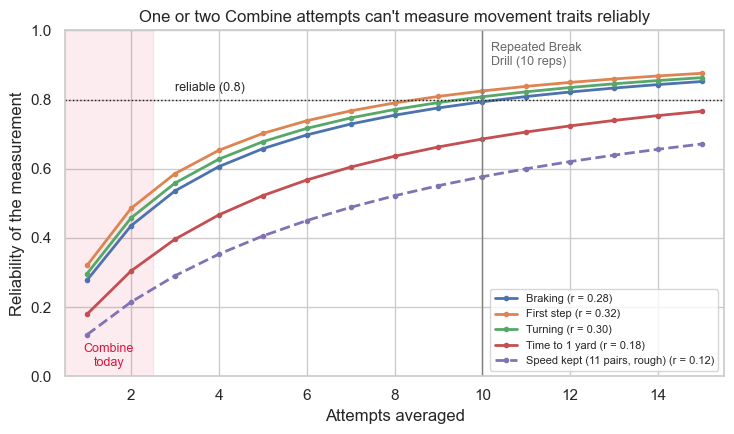

In [8]:
rel_path = Path("outputs/rookie_injury/measurement_reliability.csv")
if rel_path.exists():
    rel = pd.read_csv(rel_path)[["measure", "attempt1_vs_2_r", "player_drill_pairs"]]
else:
    rel = pd.DataFrame(dict(measure=["max_decel", "first_step", "max_turn", "time_1yd"],
                            attempt1_vs_2_r=[0.28, 0.32, 0.30, 0.18], player_drill_pairs=[894, 894, 893, 893]))
rel = pd.concat([rel, pd.DataFrame(dict(measure=["retention"], attempt1_vs_2_r=[0.12], player_drill_pairs=[11]))])
names = {"max_decel": "Braking", "first_step": "First step", "max_turn": "Turning", "time_1yd": "Time to 1 yard",
         "retention": "Speed kept (11 pairs, rough)"}
k = np.arange(1, 16)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for _, r in rel.iterrows():
    rr = r.attempt1_vs_2_r
    ax.plot(k, k * rr / (1 + (k - 1) * rr), marker="o", ms=3, lw=2,
            ls="--" if r.measure == "retention" else "-", label=f"{names.get(r.measure, r.measure)} (r = {rr:.2f})")
ax.axhline(0.8, color="k", lw=1, ls=":"); ax.text(3.0, 0.815, "reliable (0.8)", ha="left", va="bottom", fontsize=9)
ax.axvspan(0.5, 2.5, color="crimson", alpha=0.08); ax.text(1.5, 0.03, "Combine\ntoday", ha="center", fontsize=9, color="crimson")
ax.axvline(10, color="grey", lw=1); ax.text(10.2, 0.9, "Repeated Break\nDrill (10 reps)", fontsize=9, color="dimgrey")
ax.set_xlabel("Attempts averaged"); ax.set_ylabel("Reliability of the measurement"); ax.set_ylim(0, 1); ax.set_xlim(0.5, 15.5)
ax.set_title("One or two Combine attempts can't measure movement traits reliably")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout()
plt.savefig(FIG_DIR / "reliability_by_reps.png", dpi=200); plt.show()

In [9]:
import numpy as np
import pandas as pd
from pathlib import Path

# --- load (needs the rookie-injury notebook to have run once, which saved the cache) ---
att = pd.read_parquet(Path("outputs/rookie_injury/combine_attempts.parquet"))
combine_trk = pd.read_csv("../data/combine_tracking.csv")

REL_MEAS = ["retention", "max_decel", "first_step", "max_turn", "time_1yd"]
z = att[att.attempt.isin([1, 2])].copy()
z[REL_MEAS] = z.groupby("drill_name")[REL_MEAS].transform(lambda x: (x - x.mean()) / x.std())
rng = np.random.default_rng(0)


def r_with_ci(w, n_boot=1000):
    r = w[1].corr(w[2], method="spearman")
    boots = [w.iloc[i][1].corr(w.iloc[i][2], method="spearman")
             for i in (rng.integers(0, len(w), len(w)) for _ in range(n_boot))]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    reps = lambda x: 0.8 * (1 - x) / (x * 0.2) if x > 0 else np.inf
    return dict(pairs=len(w), r=round(r, 2), r_95ci=f"[{lo:.2f}, {hi:.2f}]",
                reps_for_0_8=round(reps(r), 1), reps_95ci=f"[{reps(hi):.1f}, {reps(lo):.1f}]")


# 1 + 2: movement traits with confidence intervals
rows = []
for m in ["max_decel", "first_step", "max_turn", "time_1yd"]:
    w = z.pivot_table(index=["nfl_id", "drill_name"], columns="attempt", values=m).dropna()
    rows.append(dict(measure=m) | r_with_ci(w))

# 1: benchmark, sprint times from the 40-yard dash tracking
f40 = combine_trk[combine_trk.drill_name.astype(str).str.upper().str.contains("FORTY")].copy()
f40["time"] = pd.to_datetime(f40.time, format="mixed")
f40 = f40.sort_values(["nfl_id", "event_id", "time"])
start = f40.time.where(f40.s >= 0.3).groupby([f40.nfl_id, f40.event_id]).transform("min")
f40["t"] = (f40.time - start).dt.total_seconds()
f40 = f40[f40.t >= 0]
g = f40.groupby(["nfl_id", "event_id"])
f40["disp"] = np.hypot(f40.x - g.x.transform("first"), f40.y - g.y.transform("first"))
for d, col in [(10, "sprint_10yd"), (40, "sprint_40yd")]:
    tt = f40[f40.disp >= d].groupby(["nfl_id", "attempt"]).t.min().unstack("attempt")
    if {1, 2} <= set(tt.columns):
        rows.append(dict(measure=col) | r_with_ci(tt[[1, 2]].dropna()))
rel_ci = pd.DataFrame(rows)
display(rel_ci)

# 3: selection check, attempt-1 values for players with vs without a second attempt
has2 = att.groupby(["nfl_id", "drill_name"]).attempt.transform("max") >= 2
a1 = att[att.attempt == 1].assign(has_second=has2[att.attempt == 1])
a1[REL_MEAS] = a1.groupby("drill_name")[REL_MEAS].transform(lambda x: (x - x.mean()) / x.std())
display(a1.groupby("has_second")[["max_decel", "first_step", "max_turn"]].mean().round(2))

,measure,pairs,r,r_95ci,reps_for_0_8,reps_95ci
0,max_decel,894,0.28,"[0.21, 0.34]",10.4,"[7.7, 15.2]"
1,first_step,894,0.32,"[0.25, 0.38]",8.5,"[6.5, 12.0]"
2,max_turn,893,0.30,"[0.23, 0.36]",9.5,"[7.1, 13.2]"
3,time_1yd,893,0.18,"[0.11, 0.25]",18.3,"[12.1, 31.3]"
4,sprint_10yd,302,0.54,"[0.45, 0.63]",3.3,"[2.4, 4.9]"
5,sprint_40yd,201,0.84,"[0.78, 0.90]",0.7,"[0.5, 1.1]"


,max_decel,first_step,max_turn
has_second,,,
False,0.02,0.00,0.01
True,-0.05,-0.01,-0.03


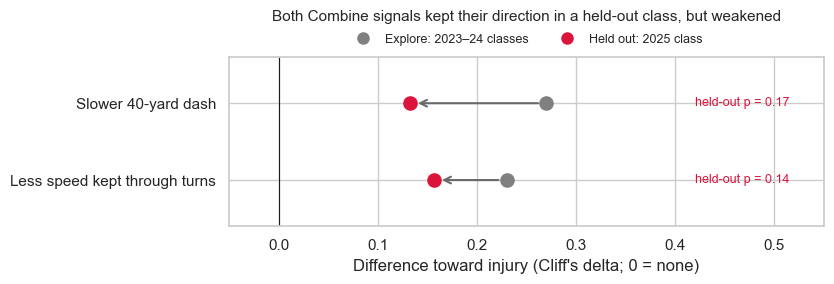

In [10]:
conf_path = Path("outputs/rookie_injury/confirmation_results.csv")
held = pd.DataFrame(dict(test=["Slower 40", "Less speed kept through turns"], explore=[0.27, -0.23],
                         holdout=[0.13, -0.16], p=[0.17, 0.14]))
if conf_path.exists():
    c = pd.read_csv(conf_path)
    c = c[c.effect_type == "Cliff's delta"].reset_index(drop=True)
    if len(c) == 2:
        held["holdout"], held["p"] = c.effect.values, c.p_value.values
held["test"] = ["Slower 40-yard dash", "Less speed kept through turns"]
sign = np.sign(held.explore)                       # predicted direction = the exploration direction
fig, ax = plt.subplots(figsize=(8.5, 3))
y = np.arange(len(held))[::-1]
for yi, (_, r), sg in zip(y, held.iterrows(), sign):
    ax.annotate("", xy=(r.holdout * sg, yi), xytext=(r.explore * sg, yi),
                arrowprops=dict(arrowstyle="->", color="dimgrey", lw=1.5, shrinkA=6, shrinkB=6))
    ax.scatter(r.explore * sg, yi, color="grey", s=90, zorder=3)
    ax.scatter(r.holdout * sg, yi, color="crimson", s=90, zorder=3)
    ax.text(0.42, yi, f"held-out p = {r.p:.2f}", va="center", fontsize=9, color="crimson")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(held.test)
ax.set_xlim(-0.05, 0.55); ax.set_ylim(-0.6, len(held) - 0.4)
ax.set_xlabel("Difference toward injury (Cliff's delta; 0 = none)")
handles = [plt.Line2D([], [], marker="o", ls="", color="grey", ms=8, label="Explore: 2023–24 classes"),
           plt.Line2D([], [], marker="o", ls="", color="crimson", ms=8, label="Held out: 2025 class")]
ax.legend(handles=handles, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
ax.set_title("Both Combine signals kept their direction in a held-out class, but weakened", pad=26, fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / "held_out_tests.png", dpi=200); plt.show()

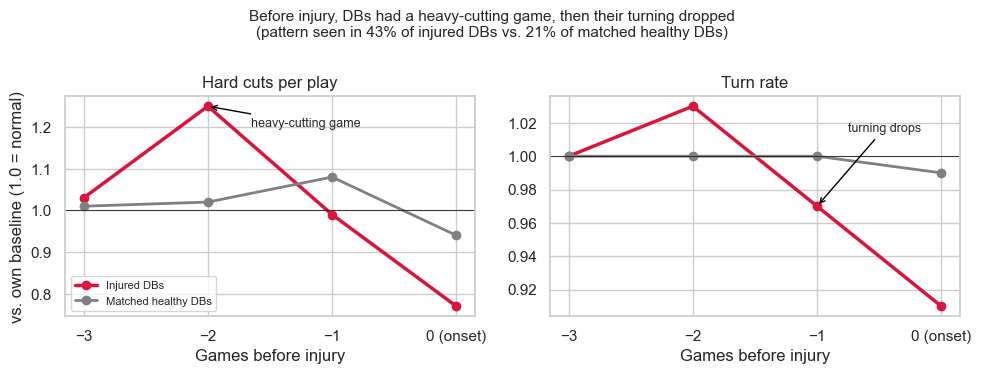

figures saved to C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\Ben_EDA\outputs\pitch_figures


In [11]:
# DB load-then-decline sequence (recorded results from bdb2027_db_injury_risk.ipynb; 28 injured DBs, 62 matched controls)
seq = pd.DataFrame(dict(game=["−3", "−2", "−1", "0 (onset)"],
                        cuts_inj=[1.03, 1.25, 0.99, 0.77], cuts_ctl=[1.01, 1.02, 1.08, 0.94],
                        turn_inj=[1.00, 1.03, 0.97, 0.91], turn_ctl=[1.00, 1.00, 1.00, 0.99]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, (a, b, title) in zip(axes, [("cuts_inj", "cuts_ctl", "Hard cuts per play"), ("turn_inj", "turn_ctl", "Turn rate")]):
    ax.plot(seq.game, seq[a], marker="o", color="crimson", lw=2.5, label="Injured DBs")
    ax.plot(seq.game, seq[b], marker="o", color="grey", lw=2, label="Matched healthy DBs")
    ax.axhline(1, color="k", lw=0.6); ax.set_title(title); ax.set_xlabel("Games before injury")
axes[0].set_ylabel("vs. own baseline (1.0 = normal)")
axes[0].annotate("heavy-cutting game", (1, 1.25), (1.35, 1.2), fontsize=9,
                 arrowprops=dict(arrowstyle="->", color="black"))
axes[1].annotate("turning drops", (2, 0.97), (2.25, 1.015), fontsize=9,
                 arrowprops=dict(arrowstyle="->", color="black"))
axes[0].legend(fontsize=8)
fig.suptitle("Before injury, DBs had a heavy-cutting game, then their turning dropped\n"
             "(pattern seen in 43% of injured DBs vs. 21% of matched healthy DBs)", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.98)); plt.savefig(FIG_DIR / "db_load_then_decline.png", dpi=200); plt.show()
print("figures saved to", FIG_DIR.resolve())